In [ ]:

# SCRAPING ULASAN GOOGLE PLAY STORE

# Install dan import library
!pip install google-play-scraper

import pandas as pd
from google_play_scraper import Sort, reviews
from datetime import datetime

# 1. KONFIGURASI SCRAPING

app_id = 'in.startv.hotstar.dplus'  # CUSTOM: ID aplikasi Google Play Store
lang = 'id'                         # CUSTOM: Bahasa ulasan
country = 'id'                      # CUSTOM: Negara pengambilan data
jumlah_data = 15000                 # CUSTOM: Maksimal jumlah ulasan

# 2. PENGAMBILAN DATA

result, _ = reviews(
    app_id,
    lang=lang,
    country=country,
    sort=Sort.NEWEST,
    count=jumlah_data
)

df = pd.DataFrame(result)


# 3. FILTER TANGGAL ULASAN

start_date = '2025-11-01'  # CUSTOM: Tanggal awal (YYYY-MM-DD)
end_date = '2026-04-30'    # CUSTOM: Tanggal akhir (YYYY-MM-DD)

df['at'] = pd.to_datetime(df['at'])

df_filtered = df[
    (df['at'] >= start_date) &
    (df['at'] < pd.to_datetime(end_date) + pd.Timedelta(days=1))
].copy()


# 4. SELEKSI DATA


# CUSTOM: Ubah kolom sesuai kebutuhan penelitian
kolom = ['userName', 'score', 'at', 'content']

df_final = df_filtered[kolom].copy()


# 5. SIMPAN DATASET

nama_file = 'data_disney_nov_2025_april_2026.csv'  # CUSTOM: Nama file output

df_final.to_csv(nama_file, index=False, encoding='utf-8-sig')


# 6. HASIL SCRAPING

print(" HASIL SCRAPING ")
print(f"Total ulasan diperoleh : {len(df)}")
print(f"Total setelah filter   : {len(df_final)}")
print(f"Periode                 : {start_date} s.d. {end_date}")
print(f"File tersimpan          : {nama_file}")

if not df_final.empty:
    print(f"Tanggal paling awal     : {df_final['at'].min()}")
    print(f"Tanggal paling akhir    : {df_final['at'].max()}")
    display(df_final.head())
else:
    print("Tidak ada ulasan dalam rentang tanggal tersebut.")
# pada tahap ini hasil scraping hanya tersimpan di session google colab. anda bisa langsung mengunduhnya di menu file pada google colab untuk menyimpanya di desktop atau bisa langsung melanjutkan ke tahap selanjutnya tanpa menyimpan

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
Total data asli: 15000
Total data setelah filter (Jan-April 2026): 1290
Rentang data: 2025-11-01 01:22:27 sampai 2026-04-29 16:18:55


,userName,score,at,content
1791,Pengguna Google,3,2026-04-29 16:18:55,Banyakkin Film Lama dan Film Baru min
1792,Pengguna Google,1,2026-04-29 12:39:24,login berkali kali tapi gagal terus balik lagi...
1793,Pengguna Google,1,2026-04-29 10:16:06,apk ga jelas masa masuk juga susah
1794,Pengguna Google,2,2026-04-29 03:52:11,knp ini gk bisa bayar y pakai gopay udh berkal...
1795,Pengguna Google,1,2026-04-28 16:50:47,sekelas disney aplikasinya sampah banget bulan...


In [1]:

# @title INSTALASI DAN IMPORT LIBRARY
# Install Library
!pip install -q Sastrawi
!pip install -q nltk
!pip install -q emoji
!pip install -q wordcloud
!pip install -q imbalanced-learn
!pip install -q openpyxl
!pip install transformers
!pip install torch

# Import Library

import nltk
import numpy as np
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('stopwords')


print("SEMUA LIBRARY BERHASIL DIMUAT")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


SEMUA LIBRARY BERHASIL DIMUAT


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [11]:
# @title MEMBUAT FOLDER PENELITIAN
from google.colab import drive
import os

# Mount Google Drive (Opsional jika dijalankan di Google Colab)
drive.mount('/content/drive')

# Tentukan direktori utama proyek Anda di Google Drive
BASE_DIR = "/content/drive/MyDrive/Analisis-Sentimen-Ulasan-Disney +"

# Daftar folder yang dibutuhkan dalam penelitian
folders = [
    "Dataset",
    "Kamus"
]

# Membuat folder secara otomatis jika belum ada
for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)
    print("📁 Dibuat/Ditemukan:", os.path.join(BASE_DIR, folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Dibuat/Ditemukan: /content/drive/MyDrive/Analisis-Sentimen-Ulasan-Disney +/Dataset
📁 Dibuat/Ditemukan: /content/drive/MyDrive/Analisis-Sentimen-Ulasan-Disney +/Kamus


In [3]:
import pandas as pd

DATASET = "/content/drive/MyDrive/Analisis-Sentimen-Ulasan-Disney +/Dataset/data_disney.csv"

df = pd.read_csv(DATASET)

df.head()

,userName,score,at,content
0,Pengguna Google,1,2026-04-25 17:21:03,udah berkali-kali login tapi gabisa
1,Pengguna Google,1,2026-04-25 17:06:36,"SANGAT TIDAK RECOMENDED. login gagal terus, pa..."
2,Pengguna Google,1,2026-04-25 15:08:34,jujur baru pertama kali dan mau buat akun cuma...
3,Pengguna Google,1,2026-04-25 15:08:29,"udh bayar, gabisa login sayang sayangin pulsa"
4,Pengguna Google,1,2026-04-25 14:42:55,"mau login aja susah kodenya ngga masuk² , tolo..."


In [4]:

# @title PREPROCESSING TAHAP 1 : CASE FOLDING

import pandas as pd

def case_folding(text):
    if pd.isna(text):
        return ""
    return str(text).lower()

# Proses Case Folding
df["casefolding"] = df["content"].apply(case_folding)

print("HASIL CASE FOLDING")

display(df[["content","casefolding"]].head(10))

HASIL CASE FOLDING


,content,casefolding
0,udah berkali-kali login tapi gabisa,udah berkali-kali login tapi gabisa
1,"SANGAT TIDAK RECOMENDED. login gagal terus, pa...","sangat tidak recomended. login gagal terus, pa..."
2,jujur baru pertama kali dan mau buat akun cuma...,jujur baru pertama kali dan mau buat akun cuma...
3,"udh bayar, gabisa login sayang sayangin pulsa","udh bayar, gabisa login sayang sayangin pulsa"
4,"mau login aja susah kodenya ngga masuk² , tolo...","mau login aja susah kodenya ngga masuk² , tolo..."
5,"udah bayar langganan, giliran mau login kode o...","udah bayar langganan, giliran mau login kode o..."
6,otp ga di kirim,otp ga di kirim
7,"perasaan dlu pas login cepett, dan lgsg masuk ...","perasaan dlu pas login cepett, dan lgsg masuk ..."
8,"gabisa nonton katanya kebanyakan yg make, lol ...","gabisa nonton katanya kebanyakan yg make, lol ..."
9,loginnya susah,loginnya susah


In [5]:


# @title TAHAP 2 : CLEANING

import re
import string
import emoji

def cleaning(text):

    if pd.isna(text):
        return ""
    text = str(text)

    # Hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Hapus HTML
    text = re.sub(r'<.*?>', ' ', text)

    # Hapus Mention
    text = re.sub(r'@\w+', ' ', text)

    # Hapus Hashtag
    text = re.sub(r'#', '', text)

    # Hapus Emoji
    text = emoji.replace_emoji(text, replace='')

    # Hapus Angka
    text = re.sub(r'\d+', ' ', text)

    # Hapus Tanda Baca
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Hapus Karakter Khusus
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Hapus Spasi Berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Proses Cleaning
df["cleaning"] = df["casefolding"].apply(cleaning)

print("HASIL CLEANING")

display(df[["casefolding","cleaning"]].head(10))

HASIL CLEANING


,casefolding,cleaning
0,udah berkali-kali login tapi gabisa,udah berkalikali login tapi gabisa
1,"sangat tidak recomended. login gagal terus, pa...",sangat tidak recomended login gagal terus pada...
2,jujur baru pertama kali dan mau buat akun cuma...,jujur baru pertama kali dan mau buat akun cuma...
3,"udh bayar, gabisa login sayang sayangin pulsa",udh bayar gabisa login sayang sayangin pulsa
4,"mau login aja susah kodenya ngga masuk² , tolo...",mau login aja susah kodenya ngga masuk tolong ...
5,"udah bayar langganan, giliran mau login kode o...",udah bayar langganan giliran mau login kode ot...
6,otp ga di kirim,otp ga di kirim
7,"perasaan dlu pas login cepett, dan lgsg masuk ...",perasaan dlu pas login cepett dan lgsg masuk k...
8,"gabisa nonton katanya kebanyakan yg make, lol ...",gabisa nonton katanya kebanyakan yg make lol p...
9,loginnya susah,loginnya susah


In [13]:
# @title TAHAP 3 : NORMALIZATION


# 1. Membaca Kamus Normalisasi menggunakan BASE_DIR
kamus_path = os.path.join(BASE_DIR, "Kamus", "colloquial-indonesian-lexicon.csv")
# Catatan: Jika file kamus Anda berada di folder "Lexicon", pastikan path-nya sesuai.

kamus = pd.read_csv(kamus_path)

# Membuat Dictionary dari kamus leksikon
normalization_dict = dict(
    zip(
        kamus["slang"],
        kamus["formal"]
    )
)

# Kamus Tambahan (Slang khusus ulasan Disney+ / aplikasi)
custom_dict = {
    "gabisa": "tidak bisa",
    "gbs": "tidak bisa",
    "gaada": "tidak ada",
    "gadapet": "tidak dapat",
    "gakdapet": "tidak dapat",
    "loginn": "login",
    "loginnya": "login",
    "otpnya": "otp",
    "lemottt": "lemot",
    "lemott": "lemot",
    "erorr": "error",
    "eror": "error",
    "ngelag": "lag",
    "ngeload": "loading",
    "loadingnya": "loading",
    "buff": "buffering",
    "langganannya": "langganan"
}

# Menggabungkan kamus utama dengan kamus tambahan
normalization_dict.update(custom_dict)


# Fungsi Normalisasi Teks
def normalization(text):
    if pd.isna(text):
        return ""

    words = str(text).split()
    hasil = []

    for word in words:
        # Mengganti kata jika ada di kamus, jika tidak biarkan tetap
        hasil.append(
            normalization_dict.get(word, word)
        )

    return " ".join(hasil)


# Proses Normalisasi pada kolom 'cleaning'
df["normalization"] = df["cleaning"].apply(normalization)

print("✅ HASIL NORMALIZATION BERHASIL DIJALANKAN")
print(f"📊 Jumlah total kamus normalisasi: {len(normalization_dict)}")

# Menampilkan 5 baris teratas perbandingan
display(
    df[
        [
            "cleaning",
            "normalization"
        ]
    ].head(5)
)

✅ HASIL NORMALIZATION BERHASIL DIJALANKAN
📊 Jumlah total kamus normalisasi: 4345


,cleaning,normalization
0,udah berkalikali login tapi gabisa,sudah berkalikali login tapi tidak bisa
1,sangat tidak recomended login gagal terus pada...,sangat tidak recomended login gagal terus pada...
2,jujur baru pertama kali dan mau buat akun cuma...,jujur baru pertama kali dan mau buat akun cuma...
3,udh bayar gabisa login sayang sayangin pulsa,sudah bayar tidak bisa login sayang sayangin p...
4,mau login aja susah kodenya ngga masuk tolong ...,mau login saja susah kodenya enggak masuk tolo...


In [14]:

# @title TAHAP 4 : TOKENIZING

# Fungsi Tokenizing menggunakan RegEx untuk mengambil kata saja

def tokenizing(text):
    return re.findall(r'\b\w+\b', text)

# Proses Tokenizing
df["tokenizing"] = df["normalization"].apply(tokenizing)

print("HASIL TOKENIZING")


display(df[["normalization","tokenizing"]].head(10))

HASIL TOKENIZING


,normalization,tokenizing
0,sudah berkalikali login tapi tidak bisa,"[sudah, berkalikali, login, tapi, tidak, bisa]"
1,sangat tidak recomended login gagal terus pada...,"[sangat, tidak, recomended, login, gagal, teru..."
2,jujur baru pertama kali dan mau buat akun cuma...,"[jujur, baru, pertama, kali, dan, mau, buat, a..."
3,sudah bayar tidak bisa login sayang sayangin p...,"[sudah, bayar, tidak, bisa, login, sayang, say..."
4,mau login saja susah kodenya enggak masuk tolo...,"[mau, login, saja, susah, kodenya, enggak, mas..."
5,sudah bayar langganan giliran mau login kode o...,"[sudah, bayar, langganan, giliran, mau, login,..."
6,otp enggak di kirim,"[otp, enggak, di, kirim]"
7,perasaan dulu pas login cepett dan langsung ma...,"[perasaan, dulu, pas, login, cepett, dan, lang..."
8,tidak bisa menonton katanya kebanyakan yang me...,"[tidak, bisa, menonton, katanya, kebanyakan, y..."
9,login susah,"[login, susah]"


In [15]:
# @title Tahapan Stopword Removal
import ast
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# MEMBUAT KAMUS CUSTOM STOPWORD

factory = StopWordRemoverFactory()
stopwords_bawaan = factory.get_stop_words()

# Daftar kata negasi & kata penting yang TIDAK BOLEH dihapus

kata_negasi = ["tidak", "bukan", "belum", "jangan", "kurang", "enggak", "ga", "gk", "gak", "gabisa"]

# Membuat daftar stopword baru: Stopword Bawaan dikurangi Kata Negasi
custom_stopwords = set([kata for kata in stopwords_bawaan if kata not in kata_negasi])

# FUNGSI PENGHAPUSAN STOPWORD

def remove_custom_stopwords(text):
    if isinstance(text, float) or text is None:
        return []
    # Deteksi format data
    try:
        words = ast.literal_eval(str(text))
        if not isinstance(words, list):
            words = str(text).split()
    except (ValueError, SyntaxError):
        words = str(text).split()

    # Filter kata: Simpan kata yang TIDAK ADA di dalam custom_stopwords
    filtered_words = [word for word in words if word not in custom_stopwords]

    # Menggabungkan kembali kata-kata yang selamat menggunakan spasi
    return " ".join(filtered_words)


# EKSEKUSI PADA DATAFRAME
print("2. Memulai proses Stopword Removal...")

df["stopword"] = df["tokenizing"].apply(remove_custom_stopwords)

print("\n" + "="*50)
print("SAMPEL HASIL CUSTOM STOPWORD")
print("="*50)
display(df[["tokenizing", "stopword"]].head(10))

2. Memulai proses Stopword Removal...

SAMPEL HASIL CUSTOM STOPWORD


,tokenizing,stopword
0,"[sudah, berkalikali, login, tapi, tidak, bisa]",berkalikali login tidak
1,"[sangat, tidak, recomended, login, gagal, teru...",sangat tidak recomended login gagal terus pada...
2,"[jujur, baru, pertama, kali, dan, mau, buat, a...",jujur baru pertama kali mau buat akun cuma eng...
3,"[sudah, bayar, tidak, bisa, login, sayang, say...",bayar tidak login sayang sayangin pulsa
4,"[mau, login, saja, susah, kodenya, enggak, mas...",mau login susah kodenya enggak masuk perbaiki ...
5,"[sudah, bayar, langganan, giliran, mau, login,...",bayar langganan giliran mau login kode otp eng...
6,"[otp, enggak, di, kirim]",otp enggak kirim
7,"[perasaan, dulu, pas, login, cepett, dan, lang...",perasaan dulu pas login cepett langsung masuk ...
8,"[tidak, bisa, menonton, katanya, kebanyakan, y...",tidak menonton katanya kebanyakan memakai lol ...
9,"[login, susah]",login susah


In [ ]:
# @title LABELING MENGGUNAKAN ROBERTA
import os
from transformers import pipeline

# 1. Load Model Sentimen Bahasa Indonesia berbasis Transformer (RoBERTa)
# Model ini digunakan untuk melakukan pseudo-labeling secara otomatis pada ulasan pengguna
classifier = pipeline(
    "sentiment-analysis",
    model="w11wo/indonesian-roberta-base-sentiment-classifier"
)

# 2. Fungsi untuk melakukan prediksi sentimen dan mengambil skor confidence
def indobert_label(text):
    if pd.isna(text) or str(text).strip() == "":
        return pd.Series(["Netral", 0.0])

    try:
        # Melakukan prediksi teks menggunakan model RoBERTa
        hasil = classifier(str(text))[0]

        label = hasil["label"]
        score = hasil["score"]

        # Konversi label model ke dalam bahasa Indonesia
        if label.upper() == "POSITIVE":
            sentiment = "Positif"
        elif label.upper() == "NEGATIVE":
            sentiment = "Negatif"
        else:
            sentiment = "Netral"

        return pd.Series([sentiment, score])

    except Exception as e:
        return pd.Series(["Netral", 0.0])


# 3. Proses Eksekusi Labeling pada DataFrame
input_column = "stopword"

print(f" Memulai proses labeling menggunakan model RoBERTa pada kolom '{input_column}'...")
df[
    [
        "label",
        "confidence"
    ]
] = df[input_column].apply(indobert_label)

print("\n HASIL LABELING SELESAI")
display(
    df[
        [
            input_column,
            "label",
            "confidence"
        ]
    ].head(5)
)

print("\n Distribusi Label Sentimen:")
print(df["label"].value_counts())


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 Memulai proses labeling menggunakan model RoBERTa pada kolom 'stopword'...


In [ ]:
# @title MENGHAPUS DATA NETRAL

# Menyimpan jumlah data sebelum difilter untuk perbandingan
jumlah_awal = len(df)

# Memfilter DataFrame untuk menghapus baris dengan label "Netral"
# (sehingga hanya menyisakan kelas Positif dan Negatif)
df = df[df["label"] != "Netral"].reset_index(drop=True)

jumlah_akhir = len(df)

print(" PENGHAPUSAN DATA NETRAL SELESAI")
print(f"Jumlah data sebelum : {jumlah_awal}")
print(f"Jumlah data sesudah : {jumlah_akhir}")
print(f"Data netral dihapus : {jumlah_awal - jumlah_akhir}")

print("\n Distribusi Label Setelah Filter:")
print(df["label"].value_counts())

print("\nContoh Data Setelah Penghapusan Label Netral:")
display(df[["stopword", "label", "confidence"]].head(5))

PENGHAPUSAN DATA NETRAL
Jumlah data sebelum : 1271
Jumlah data sesudah : 1058
Data netral dihapus : 213

Distribusi Label
label
Negatif    989
Positif     69
Name: count, dtype: int64

Contoh Data Setelah Penghapusan Label Netral


,stemming,label,confidence
0,berkalikali login tidak,Negatif,0.713826
1,sangat tidak recomended login gagal terus pada...,Negatif,0.997968
2,jujur baru pertama kali mau buat akun cuma eng...,Negatif,0.999234
3,bayar langgan gilir mau login kode otp enggak ...,Negatif,0.789557
4,otp enggak kirim,Negatif,0.990585
5,asa dulu pas login cepett langsung masuk kode ...,Negatif,0.998623
6,tidak tonton kata banyak pakai lol padahal log...,Negatif,0.986578
7,login susah,Negatif,0.997803
8,enggak daftar,Negatif,0.983478
9,sumpah enggak jelas banget nih apk bolakbalik ...,Negatif,0.999291


In [ ]:
# @title DATA SPLITTING (MENCEGAH DATA LEAKAGE)
from sklearn.model_selection import train_test_split

# Menentukan Fitur (X) dan Label (y)
X = df["stopword"]
y = df["label"]

# Membagi dataset menjadi Data Latih (Train) dan Data Uji (Test) dengan proporsi 80:20
# Parameter 'stratify=y' memastikan proporsi kelas Positif dan Negatif
# seimbang antara data latih dan data uji.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(" DATA SPLITTING BERHASIL")
print(f" Jumlah Total Data : {len(df)}")
print(f" Jumlah Data Latih : {len(X_train)} (80%)")
print(f" Jumlah Data Uji   : {len(X_test)} (20%)")

# Menampilkan distribusi kelas pada data latih dan uji untuk verifikasi stratifikasi
print("\nDistribusi Label pada Data Latih:")
print(y_train.value_counts())

print("\nDistribusi Label pada Data Uji:")
print(y_test.value_counts())

DATA SPLITING
Jumlah Data Latih : 846
Jumlah Data Uji   : 212


In [ ]:
# @title EKSTRAKSI FITUR TF-IDF (TERM FREQUENCY-INVERSE DOCUMENT FREQUENCY)
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Inisialisasi TfidfVectorizer
# Catatan: Anda bisa menambahkan parameter seperti max_features=5000 atau ngram_range=(1,2) jika diperlukan
tfidf = TfidfVectorizer()

# 2. Fit & Transform pada Data Latih (Train)
# 'fit_transform' mempelajari kosakata dari data latih sekaligus mengubahnya menjadi matriks angka
X_train_tfidf = tfidf.fit_transform(X_train)

# 3. Transform pada Data Uji (Test)
# 'transform' HANYA mengubah data uji berdasarkan kosakata yang sudah dipelajari dari data latih
# (Mencegah terjadinya Data Leakage)
X_test_tfidf = tfidf.transform(X_test)

print(" EKSTRAKSI FITUR TF-IDF BERHASIL")
print(f"Ukuran matriks fitur Data Latih : {X_train_tfidf.shape}")
print(f"Ukuran matriks fitur Data Uji   : {X_test_tfidf.shape}")

# 4. Opsional: Melihat sampel bentuk DataFrame (hanya untuk visualisasi/inspeksi)
# Menggunakan .head() dengan konversi array terbatas untuk menghindari boros memori
tfidf_sample_df = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

print("\nContoh Bobot TF-IDF (5 Baris Pertama):")
display(tfidf_sample_df.iloc[:, :10]) # Menampilkan 10 kolom fitur pertama sebagai sampel

print(f"\nJumlah total fitur unik (vocabulary) yang dihasilkan : {len(tfidf.get_feature_names_out())}")

,abad,abai,able,abnormal,about,absolutely,acc,access,account,aco,...,yaklo,yaudah,yaudahlah,you,your,youre,youtube,ytsaya,zonk,zootopia
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,Fitur
0,abad
1,abai
2,able
3,abnormal
4,about


Jumlah fitur : 1753


In [ ]:
# @title PENANGANAN KETIDAKSEIMBANGAN DATA MENGGUNAKAN SMOTE

# Catatan: SMOTE digunakan  untuk menyeimbangkan jumlah sampel antara kelas minoritas dan mayoritas dengan cara membuat data sintetis hal ini bertujuan  agar model tidak  bias hanya menebak kelas mayoritas saja.
from imblearn.over_sampling import SMOTE

print(" PENANGANAN KETIDAKSEIMBANGAN DATA DENGAN SMOTE")

# 1. Menampilkan distribusi kelas pada data latih SEBELUM SMOTE
print("\nDistribusi kelas sebelum SMOTE:")
print(y_train.value_counts())

# 2. Inisialisasi dan Penerapan SMOTE
# Catatan: SMOTE HANYA diterapkan pada data latih (X_train_tfidf) untuk mencegah data leakage
# serta mengatasi bias model terhadap kelas mayoritas.
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("\n" + "="*40)
# 3. Menampilkan distribusi kelas pada data latih SESUDAH SMOTE
print("Distribusi kelas sesudah SMOTE:")
print(pd.Series(y_train_smote).value_counts())
print("="*40)
print(f" Total data latih setelah balancing: {X_train_smote.shape[0]} baris")

SMOTE
Distribusi kelas sebelum SMOTE
label
Negatif    791
Positif     55
Name: count, dtype: int64

Distribusi kelas sesudah SMOTE
label
Negatif    791
Positif    791
Name: count, dtype: int64


In [ ]:
# @title KLASIFIKASI MULTINOMIAL NAIVE BAYES (TANPA SMOTE)
from sklearn.naive_bayes import MultinomialNB

# 1. Inisialisasi Model Multinomial Naive Bayes
model_tanpa_smote = MultinomialNB()

print(" Melatih model Naive Bayes menggunakan data asli (Tanpa SMOTE)...")

# 2. Melatih model menggunakan data latih asli (X_train_tfidf & y_train)
model_tanpa_smote.fit(
    X_train_tfidf,
    y_train
)

# 3. Melakukan prediksi terhadap data uji (X_test_tfidf)
y_pred_tanpa_smote = model_tanpa_smote.predict(X_test_tfidf)

print("\n" + "="*50)
print(" MODEL TANPA SMOTE BERHASIL DILATIH & DIUJI")
print("="*50)
print(f" Jumlah data latih : {len(y_train)} baris")
print(f" Jumlah data uji   : {len(X_test_tfidf.toarray())} baris")

MULTINOMIAL NAIVE BAYES TANPA SMOTE
Jumlah data latih : 846
Jumlah data uji   : 212
Model berhasil dilatih dan diuji.


In [ ]:
# @title KLASIFIKASI MULTINOMIAL NAIVE BAYES DENGAN SMOTE
from sklearn.naive_bayes import MultinomialNB

# 1. Inisialisasi Model Multinomial Naive Bayes untuk data hasil SMOTE
model_dengan_smote = MultinomialNB()

print(" Melatih model Naive Bayes menggunakan data hasil SMOTE...")

# 2. Melatih model menggunakan data latih yang sudah seimbang (X_train_smote & y_train_smote)
model_dengan_smote.fit(
    X_train_smote,
    y_train_smote
)

# 3. Melakukan prediksi terhadap data uji murni (X_test_tfidf)
y_pred_dengan_smote = model_dengan_smote.predict(X_test_tfidf)

print("\n" + "="*50)
print(" MODEL DENGAN SMOTE BERHASIL DILATIH & DIUJI")
print("="*50)
print(f" Jumlah data latih (setelah SMOTE) : {len(y_train_smote)} baris")
print(f" Jumlah data uji (murni)           : {len(y_pred_dengan_smote)} baris")

MULTINOMIAL NAIVE BAYES DENGAN SMOTE
Jumlah data latih : 1582
Jumlah data uji   : 212
Model berhasil dilatih dan diuji.


In [ ]:
# @title EVALUASI DAN PERBANDINGAN MODEL (DENGAN & TANPA SMOTE)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Menyiapkan daftar prediksi dari kedua model untuk dievaluasi
daftar_prediksi = {
    "Tanpa SMOTE": y_pred_tanpa_smote,
    "Dengan SMOTE": y_pred_dengan_smote
}

hasil_evaluasi = []

# 2. Looping untuk menghitung metrik evaluasi masing-masing model
for nama, y_pred in daftar_prediksi.items():

    # Menyimpan ringkasan metrik performa
    hasil_evaluasi.append({
        "Model": nama,
        "Akurasi": accuracy_score(y_test, y_pred),
        "Presisi (Weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (Weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score (Weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

    # Menampilkan Classification Report yang mendetail (Precision, Recall, F1 per kelas Positif & Negatif)
    print("="*60)
    print(f" CLASSIFICATION REPORT: {nama.upper()}")
    print("="*60)
    print(classification_report(
        y_test,
        y_pred,
        labels=["Negatif", "Positif"],
        zero_division=0
    ))
    print("\n")

# 3. Membuat Tabel Perbandingan Ringkas dalam bentuk DataFrame Pandas
tabel_evaluasi = pd.DataFrame(hasil_evaluasi)

print("="*60)
print(" TABEL PERBANDINGAN PERFORMA MODEL")
print("="*60)
display(tabel_evaluasi.round(4))


Classification Report Tanpa SMOTE

              precision    recall  f1-score   support

     Negatif       0.93      1.00      0.97       198
     Positif       0.00      0.00      0.00        14

    accuracy                           0.93       212
   macro avg       0.47      0.50      0.48       212
weighted avg       0.87      0.93      0.90       212


Classification Report Dengan SMOTE

              precision    recall  f1-score   support

     Negatif       0.98      0.98      0.98       198
     Positif       0.79      0.79      0.79        14

    accuracy                           0.97       212
   macro avg       0.89      0.89      0.89       212
weighted avg       0.97      0.97      0.97       212



,Model,Akurasi,Presisi,Recall,F1-Score
0,Tanpa SMOTE,0.9340,0.8723,0.9340,0.9021
1,Dengan SMOTE,0.9717,0.9717,0.9717,0.9717


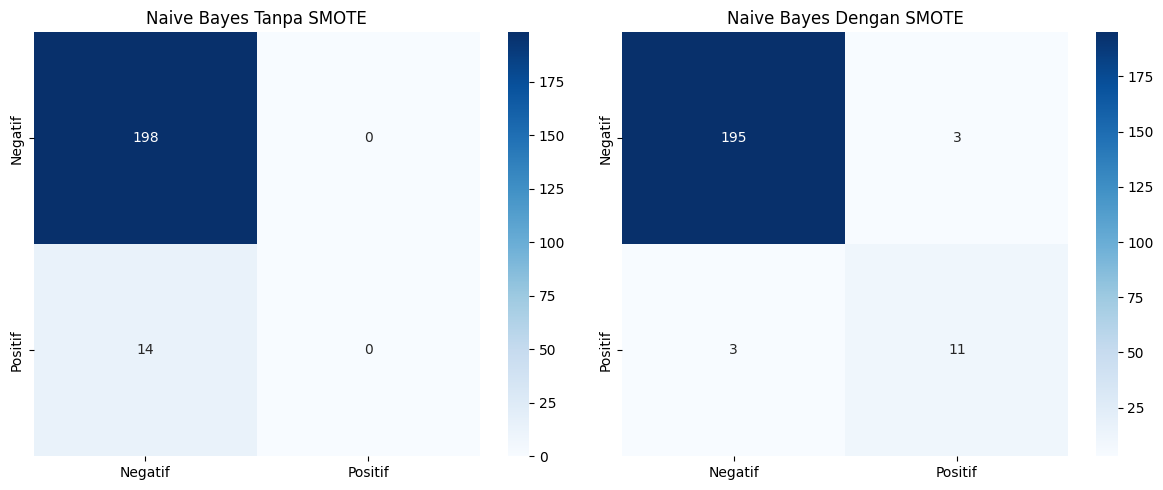

In [ ]:
# @title VISUALISASI CONFUSION MATRIX (PERBANDINGAN MODEL)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Menentukan label kelas biner
labels_kelas = ["Negatif", "Positif"]

# Membuat 1 baris, 2 kolom untuk grafik berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dictionary daftar prediksi model
models_dict = {
    "Tanpa SMOTE": y_pred_tanpa_smote,
    "Dengan SMOTE": y_pred_dengan_smote
}

for ax, (nama, prediksi) in zip(axes, models_dict.items()):
    # Menghitung confusion matrix
    cm = confusion_matrix(y_test, prediksi, labels=labels_kelas)

    # Membuat heatmap menggunakan seaborn
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels_kelas,
        yticklabels=labels_kelas,
        ax=ax,
        cbar=False
    )

    # Menambahkan judul dan label sumbu agar sesuai standar penulisan ilmiah
    ax.set_title(f"Confusion Matrix - {nama}", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)

plt.suptitle("Perbandingan Performa Model Naive Bayes", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

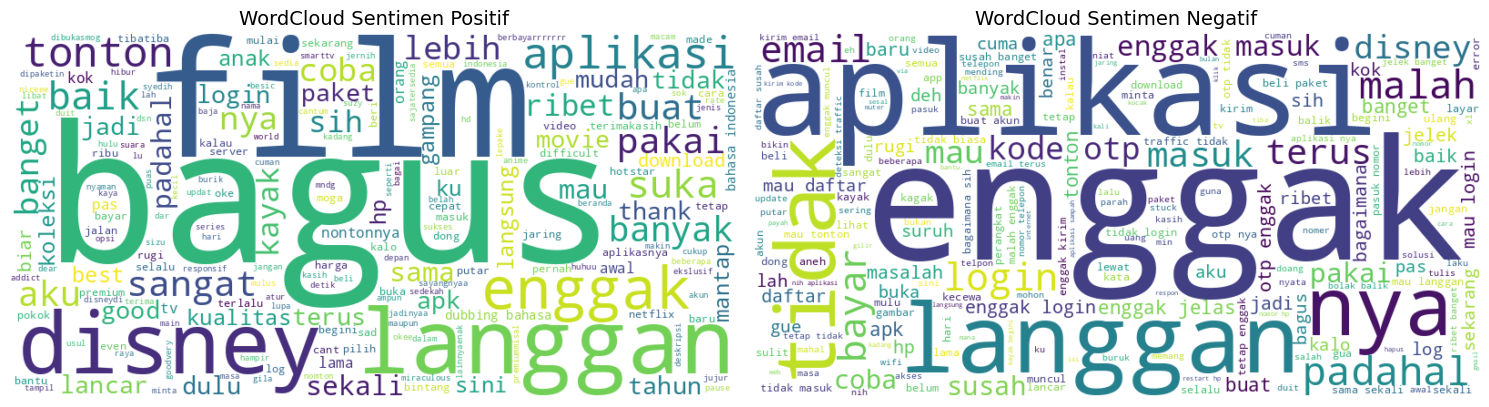

In [ ]:
# @title VISUALISASI WORDCLOUD (SENTIMEN POSITIF VS NEGATIF)
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Menggabungkan seluruh teks berdasarkan label (Positif dan Negatif)
# Menggunakan kolom 'stopword' karena tahap stemming sudah ditiadakan
positif = " ".join(df[df["label"] == "Positif"]["stopword"])
negatif = " ".join(df[df["label"] == "Negatif"]["stopword"])

# 2. Inisialisasi dan Generate WordCloud untuk Sentimen Positif
wc_pos = WordCloud(
    width=800,
    height=400,
    background_color="white",
    colormap="Greens"  # Menggunakan tema hijau untuk sentimen positif
).generate(positif)

# 3. Inisialisasi dan Generate WordCloud untuk Sentimen Negatif
wc_neg = WordCloud(
    width=800,
    height=400,
    background_color="white",
    colormap="Reds"   # Menggunakan tema merah untuk sentimen negatif
).generate(negatif)

# 4. Menampilkan WordCloud secara berdampingan menggunakan Matplotlib
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ax[0].imshow(wc_pos, interpolation="bilinear")
ax[0].set_title("WordCloud Sentimen Positif", fontsize=14, fontweight="bold", pad=10)
ax[0].axis("off")

ax[1].imshow(wc_neg, interpolation="bilinear")
ax[1].set_title("WordCloud Sentimen Negatif", fontsize=14, fontweight="bold", pad=10)
ax[1].axis("off")

plt.suptitle("Analisis Frekuensi Kata (WordCloud) Berdasarkan Sentimen", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()

# 5. Menyimpan gambar WordCloud dengan resolusi tinggi (300 DPI) untuk lampiran skripsi / GitHub
plt.savefig(
    "perbandingan_wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(" Gambar WordCloud berhasil disimpan sebagai 'perbandingan_wordcloud.png'")